## **Messwerte**

In [283]:
import numpy as np
import uncertainties as uc
import uncertainties.unumpy as unp


R_V_data = 82 #Vorwiderstand in Ohm
R_V_Fehler = 0.1
R_V = uc.ufloat(R_V_data, R_V_Fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

f_data = np.array([25, 50, 75, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 2000, 2200, 2800, 3e3, 4e3, 6e3, 8e3, 10e3, 12e3, 13e3, 15e3, 20e3, 25e3, 30e3, 40e3, 50e3])  #gemessene Frequenzen in Hz
f_fehler = 0.1
f = unp.uarray(f_data, f_fehler)
omega = f * 2* np.pi

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

U_RV_data = np.array([0.264, 0.484, 0.660, 0.8, 1.12, 1.26, 1.30, 1.34, 1.36, 1.38, 1.38, 1.38, 1.40, 1.40,1.40, 1.36, 1.38, 1.38, 1.40, 1.38, 1.38, 1.40, 1.38, 1.38, 1.36, 1.32, 1.27, 1.19, 1.11, 1.02, 0.984, 0.912, 0.744, 0.624, 0.52, 0.386, 0.298]) #Spannung am Vorwiederstand in V
U_RV_fehler = 0.01
U_RV = unp.uarray(U_RV_data, U_RV_fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

U_RLC_data = np.array([3.38, 3.26, 3.14, 2.98, 2.56, 2.32, 2.20, 2.16, 2.1, 2.06, 2.06, 2.06, 2.04, 2.04, 2.04, 1.94, 2.04, 2.04, 2.04, 2.02, 2.04, 2.04, 2.06, 2.06, 2.08, 2.18, 2.36, 2.54, 2.72, 2.88, 2.94, 3.06, 3.22, 3.34, 3.4, 3.44, 3.46]) #Spannung an der RLC Masche in V
U_RLC_fehler = 0.01
U_RLC = unp.uarray(U_RLC_data, U_RLC_fehler)

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""

deltaPhi_data = np.array([-82, -72, -70, -62.5, -50, -35, -25, -22, -19, -15, -12, -10, -8, -6, -5, 0, 1, 1.5, 4, 6, 7, 10, 12, 17, 18, 28, 40, 50, 58, 65, 68, 72, 81, 88, 90, 102, 110]) *(2*np.pi/360) #Phasenverschiebung in rad
deltaPhi_fehler = 2 *(2*np.pi /360)
deltaPhi = unp.uarray(deltaPhi_data, deltaPhi_fehler)


## **Plots und Regressionen für die Einzelbereiche**

Kapazität aus linearer Regression: C = (4.01+/-0.06)e-06 F 

Induktivität aus linearer Regression: L = 3.01+/-0.10 mH 

Resonanzfrequenz aus Fit-Minimum: omega_res = (8.4+/-0.4)e+03 1/s 

Resonanzfrequenz aus L und C: omega_res = (9.11+/-0.17)e+03 1/s 

Widerstand aus Minimum des Fits: R = 119.2+/-0.5 Ohm 

Widerstand aus Wert des Fits bei berechnetem omega_Res: R = 119.2+/-0.5 Ohm 

Stored 'R' (AffineScalarFunc)
Stored 'C' (Variable)


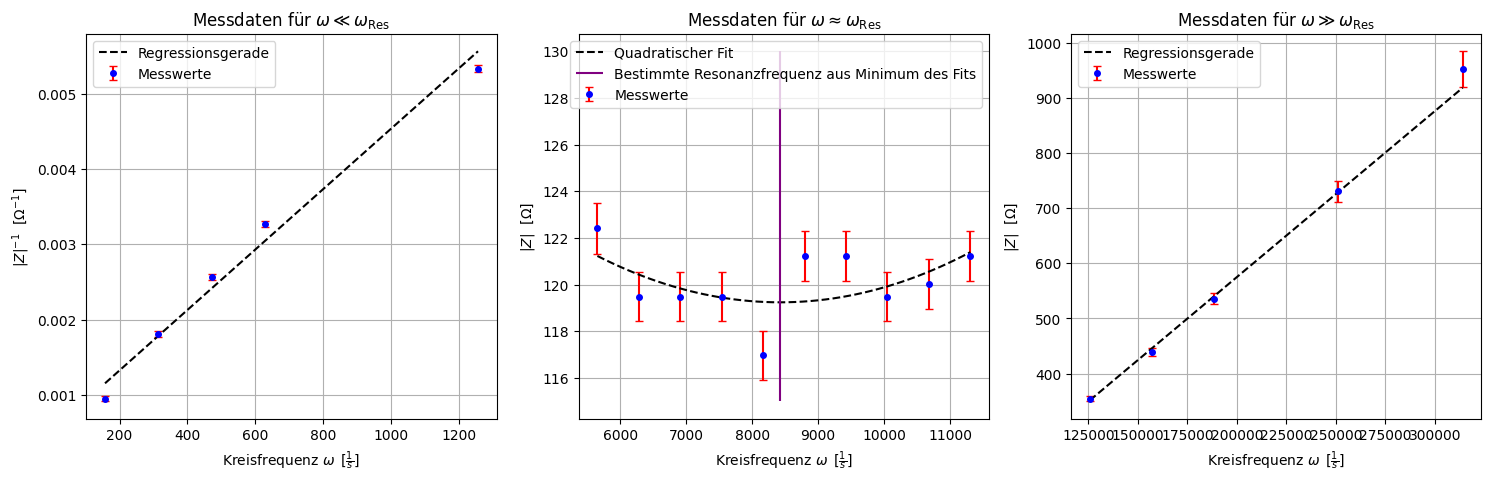

In [284]:
import scipy
import matplotlib.pyplot as plt

#Bereiche
index_smallerRes = slice(0,5) #TODO: Eintragen
index_Res = slice(11, 21) #TODO: Eintragen
index_higherRes = slice(32, len(f_data)+3) #TODO: Eintragen

#Berechnung der Impedanzen

Z = R_V * (U_RLC / U_RV) #Betrag der Impedanz in Ohm

fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (18,5))

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
# Auswertung für omega << omega_res

def f(x, k, c):
    return k*x + c

Z_inv = 1/Z

coefficients1, pcov1 = scipy.optimize.curve_fit(f, unp.nominal_values(omega)[index_smallerRes], unp.nominal_values(Z_inv)[index_smallerRes], sigma= unp.std_devs(Z_inv)[index_smallerRes], absolute_sigma= True)

C = uc.ufloat(coefficients1[0], np.sqrt(pcov1[0,0]))
c1 = coefficients1[1]

print(f"Kapazität aus linearer Regression: C = {C} F \n")

ax1.errorbar(unp.nominal_values(omega)[index_smallerRes], unp.nominal_values(Z_inv)[index_smallerRes] , yerr= unp.std_devs(Z_inv)[index_smallerRes] , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

ax1.plot(unp.nominal_values(omega)[index_smallerRes], f(unp.nominal_values(omega)[index_smallerRes], coefficients1[0],coefficients1[1] ), label = "Regressionsgerade", color = "black", linestyle = "--")

ax1.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax1.set_ylabel("$|Z|^{-1}$  $[\\Omega ^{-1}]$")
ax1.grid(True)
ax1.set_title("Messdaten für $\\omega \\ll \\omega _{\\mathrm{Res}}$")
ax1.legend()


"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
# Auswertung für omega >> omega_res

coefficients2, pcov2 = scipy.optimize.curve_fit(f, unp.nominal_values(omega)[index_higherRes], unp.nominal_values(Z)[index_higherRes], sigma= unp.std_devs(Z)[index_higherRes], absolute_sigma= True)

L = uc.ufloat(coefficients2[0], np.sqrt(pcov2[0,0]))
c2 = coefficients2[1]

print(f"Induktivität aus linearer Regression: L = {L*10**3} mH \n")

ax3.errorbar(unp.nominal_values(omega)[index_higherRes], unp.nominal_values(Z)[index_higherRes] , yerr= unp.std_devs(Z)[index_higherRes] , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

ax3.plot(unp.nominal_values(omega)[index_higherRes], f(unp.nominal_values(omega)[index_higherRes], coefficients2[0],coefficients2[1] ), label = "Regressionsgerade", color = "black", linestyle = "--")

ax3.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax3.set_ylabel("$|Z|$  $[\\Omega ]$")
ax3.grid(True)
ax3.set_title("Messdaten für $\\omega \\gg \\omega _{\\mathrm{Res}}$")
ax3.legend()


"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
# Auswertung für omega ~ omega_res

def quad(x, a, b, c):
    return a*(x**2) + b*x +c

coefficients3, pcov3 = scipy.optimize.curve_fit(quad, unp.nominal_values(omega)[index_Res], unp.nominal_values(Z)[index_Res], sigma= unp.std_devs(Z)[index_Res], absolute_sigma= True)

a, b, c = uc.correlated_values(coefficients3, pcov3)

ax2.errorbar(unp.nominal_values(omega)[index_Res], unp.nominal_values(Z)[index_Res], yerr= unp.std_devs(Z)[index_Res] , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(np.min(unp.nominal_values(omega)[index_Res]), np.max(unp.nominal_values(omega)[index_Res]))
ax2.plot(xwerte, quad(xwerte, coefficients3[0],coefficients3[1], coefficients3[2]), label = "Quadratischer Fit", color = "black", linestyle = "--")


omega_res_calc = -b/(2*a)
print(f"Resonanzfrequenz aus Fit-Minimum: omega_res = {omega_res_calc} 1/s \n")

omega_res_theo = 1/ unp.sqrt(L*C)
print(f"Resonanzfrequenz aus L und C: omega_res = {omega_res_theo} 1/s \n")


ax2.vlines(omega_res_calc.nominal_value, ymin = 115, ymax = 130, color = "purple", label = "Bestimmte Resonanzfrequenz aus Minimum des Fits")



R = c - b**2/(4*a)
print(f"Widerstand aus Minimum des Fits: R = {R} Ohm \n")

R_calc = quad(omega_res_calc, a, b, c)
print(f"Widerstand aus Wert des Fits bei berechnetem omega_Res: R = {R_calc} Ohm \n")

ax2.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax2.set_ylabel("$|Z|$  $[\\Omega ]$")
ax2.grid(True)
ax2.set_title("Messdaten für $\\omega \\approx \\omega _{\\mathrm{Res}}$")
ax2.legend()

%store R
%store C

## **Plot des gesamten Frequenzbereichs**

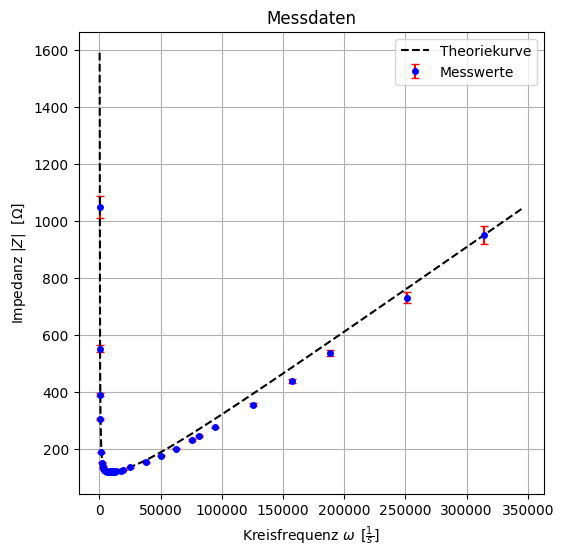

In [285]:
def func(R, omega, L, C):
    return unp.sqrt(R**2 + (omega*L - 1/(omega * C))**2)

fig, ax1 = plt.subplots(1,1, figsize = (6,6))

ax1.errorbar(unp.nominal_values(omega), unp.nominal_values(Z) , yerr= unp.std_devs(Z) , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(np.min(unp.nominal_values(omega)), np.max(unp.nominal_values(omega))*1.1, 1000)
ax1.plot(xwerte, unp.nominal_values(func(R, xwerte, L, C)), label = "Theoriekurve", color = "black", linestyle = "--")


ax1.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax1.set_ylabel("Impedanz $|Z|$  $[\\Omega ]$")
ax1.grid(True)
ax1.set_title("Messdaten")
ax1.legend()

## **Plots der Phasenverschiebung**

Resonanzfrequenz aus NST des Fits: omega_res = (8.8+/-1.4)e+03 1/s 



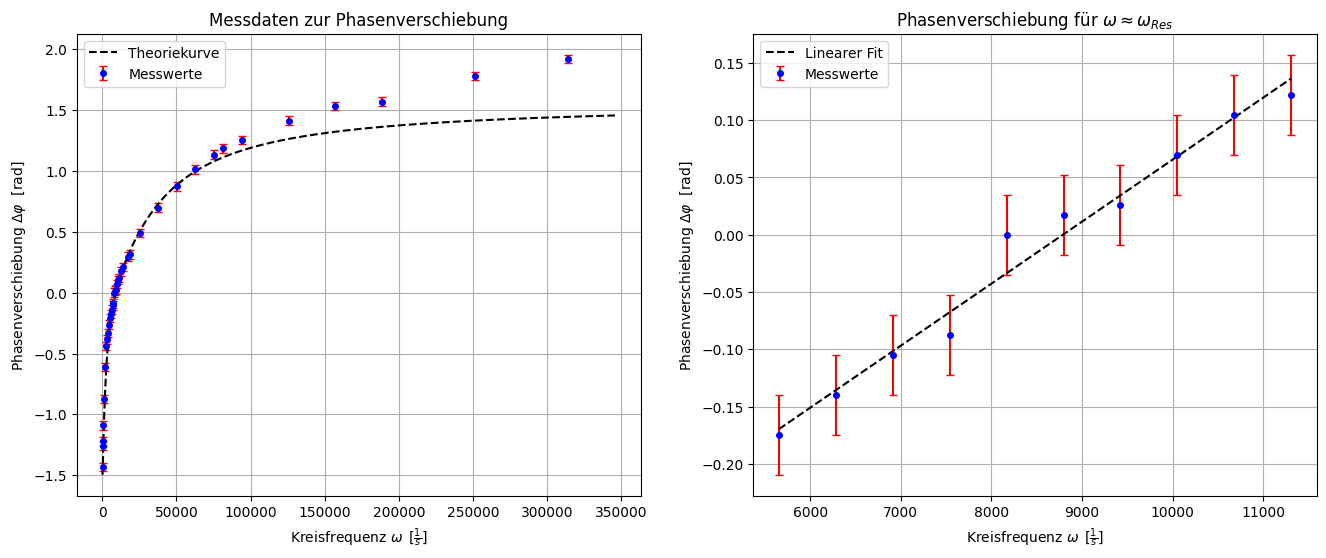

In [286]:

fig, (ax1, ax2) = plt.subplots(1,2, figsize = (16,6))

#Gesamter Bereich

ax1.errorbar(unp.nominal_values(omega), unp.nominal_values(deltaPhi) , yerr= unp.std_devs(deltaPhi) , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(np.min(unp.nominal_values(omega)), np.max(unp.nominal_values(omega))*1.1, 1000)
Theoriekurve = unp.arctan((xwerte*L - 1/(xwerte*C))/R)

ax1.plot(xwerte, unp.nominal_values(Theoriekurve), label = "Theoriekurve", color = "black", linestyle = "--")

ax1.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax1.set_ylabel("Phasenverschiebung $ \\Delta \\varphi $  [rad]")
ax1.grid(True)
ax1.set_title("Messdaten zur Phasenverschiebung")
ax1.legend()

"""-----------------------------------------------------------------------------------------------------------------------------------------------------------"""
#Nahe der Resonanzfrequenz

ax2.errorbar(unp.nominal_values(omega)[index_Res], unp.nominal_values(deltaPhi)[index_Res] , yerr= unp.std_devs(deltaPhi)[index_Res] , fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")

coefficients, pcov = scipy.optimize.curve_fit(f, unp.nominal_values(omega)[index_Res], unp.nominal_values(deltaPhi)[index_Res], sigma= unp.std_devs(deltaPhi)[index_Res], absolute_sigma= True)

k = uc.ufloat(coefficients[0], np.sqrt(pcov[0,0]))
c = uc.ufloat(coefficients[1], np.sqrt(pcov[1,1]))

xwerte = np.linspace(np.min(unp.nominal_values(omega)[index_Res]), np.max(unp.nominal_values(omega)[index_Res]), 1000)
ax2.plot(xwerte, k.nominal_value*xwerte + c.nominal_value, label = "Linearer Fit", color = "black", linestyle = "--")

omega_res_NST = (-c)/k #NST der Gerade

print(f"Resonanzfrequenz aus NST des Fits: omega_res = {omega_res_NST} 1/s \n")

ax2.set_xlabel("Kreisfrequenz $\\omega \\,$ $[\\frac{1}{s}]$")
ax2.set_ylabel("Phasenverschiebung $ \\Delta \\varphi $  [rad]")
ax2.grid(True)
ax2.set_title("Phasenverschiebung für $ \\omega \\approx \\omega _{Res} $")
ax2.legend()
